---
## Step 0 — Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print('All libraries imported successfully!')

All libraries imported successfully!


---
## Step 1 — Load the Dataset

This CSV uses a **semicolon (`;`)** as the separator, so we pass `sep=';'`.
A few columns (`Paid`, `like`, `share`) have missing values. PCA cannot handle `NaN`,
so we drop those rows (only 5 of 500).

In [2]:
fb_dataset = pd.read_csv('dataset_Facebook.csv', sep=';')
print('Original shape:', fb_dataset.shape)

print('Missing values per column:')
print(fb_dataset.isna().sum()[fb_dataset.isna().sum() > 0])

fb_dataset = fb_dataset.dropna().reset_index(drop=True)
print('Shape after dropping missing rows:', fb_dataset.shape)

fb_dataset.head()

Original shape: (500, 19)
Missing values per column:
Paid     1
like     1
share    4
dtype: int64
Shape after dropping missing rows: (495, 19)


,Page total likes,Type,Category,Post Month,Post Weekday,Post Hour,Paid,Lifetime Post Total Reach,Lifetime Post Total Impressions,Lifetime Engaged Users,Lifetime Post Consumers,Lifetime Post Consumptions,Lifetime Post Impressions by people who have liked your Page,Lifetime Post reach by people who like your Page,Lifetime People who have liked your Page and engaged with your post,comment,like,share,Total Interactions
0,139441,Photo,2,12,4,3,0.0,2752,5091,178,109,159,3078,1640,119,4,79.0,17.0,100
1,139441,Status,2,12,3,10,0.0,10460,19057,1457,1361,1674,11710,6112,1108,5,130.0,29.0,164
2,139441,Photo,3,12,3,3,0.0,2413,4373,177,113,154,2812,1503,132,0,66.0,14.0,80
3,139441,Photo,2,12,2,10,1.0,50128,87991,2211,790,1119,61027,32048,1386,58,1572.0,147.0,1777
4,139441,Photo,2,12,2,3,0.0,7244,13594,671,410,580,6228,3200,396,19,325.0,49.0,393


---
## Step 2 — Explore Features and Labels

- **Features** = every numeric column except `Type`
- **Label** = `Type` — used only for coloring the final plot


In [3]:
features = [col for col in fb_dataset.columns if col != 'Type']

print('Number of features:', len(features))
print('Feature names:', features)
print()

print('Label distribution (Type):')
print(fb_dataset['Type'].value_counts())

Number of features: 18
Feature names: ['Page total likes', 'Category', 'Post Month', 'Post Weekday', 'Post Hour', 'Paid', 'Lifetime Post Total Reach', 'Lifetime Post Total Impressions', 'Lifetime Engaged Users', 'Lifetime Post Consumers', 'Lifetime Post Consumptions', 'Lifetime Post Impressions by people who have liked your Page', 'Lifetime Post reach by people who like your Page', 'Lifetime People who have liked your Page and engaged with your post', 'comment', 'like', 'share', 'Total Interactions']

Label distribution (Type):
Type
Photo     421
Status     45
Link       22
Video       7
Name: count, dtype: int64


---
## Step 3 — Normalize (Standardize) the Features

PCA looks for directions of **maximum variance**, so features on large scales dominate.
Here `Lifetime Post Total Impressions` is in the thousands while `Category` is 1–3.
`StandardScaler` gives every feature mean = 0 and std = 1:  `z = (x - mean) / std`

In [4]:
raw_features = fb_dataset[features]
x = StandardScaler().fit_transform(raw_features)

print('Normalized data stats:')
print('  Mean : {:.6f}  (should be ~0)'.format(np.mean(x)))
print('  Std  : {:.6f}  (should be ~1)'.format(np.std(x)))
print('  Shape:', x.shape)

Normalized data stats:
  Mean : 0.000000  (should be ~0)
  Std  : 1.000000  (should be ~1)
  Shape: (495, 18)


---
## Step 4 — Apply PCA

We reduce the 18 standardized features to **2 principal components** so the data can be shown on a 2D scatter plot.

In [5]:
pca = PCA(n_components=2)
principal_components = pca.fit_transform(x)

print('PCA output shape:', principal_components.shape)

pca_df = pd.DataFrame(principal_components, columns=['PC1', 'PC2'])
print()
print('First 5 rows of PCA result:')
print(pca_df.head())

PCA output shape: (495, 2)

First 5 rows of PCA result:
        PC1       PC2
0 -1.769533  1.829945
1  0.281251  0.763142
2 -1.871393  1.875974
3  6.925546  4.027812
4 -0.207981  2.377463


---
## Step 4b — Explained Variance Ratio

In [6]:
pc1_var, pc2_var = pca.explained_variance_ratio_

print('Explained variance per principal component:')
print('  PC1 : {:.1%}'.format(pc1_var))
print('  PC2 : {:.1%}'.format(pc2_var))
print('  ──────────────────────────────────────────────')
print('  Total: {:.1%}  of original information retained in 2D'.format(pc1_var + pc2_var))

Explained variance per principal component:
  PC1 : 36.7%
  PC2 : 12.7%
  ──────────────────────────────────────────────
  Total: 49.4%  of original information retained in 2D


### Which features drive each component?
The loadings show how strongly each original feature contributes to PC1 and PC2.

In [7]:
loadings = pd.DataFrame(pca.components_.T, index=features, columns=['PC1', 'PC2'])
print(loadings.round(2))

                                                     PC1   PC2
Page total likes                                   -0.03  0.48
Category                                           -0.00  0.10
Post Month                                         -0.04  0.47
Post Weekday                                       -0.03 -0.04
Post Hour                                           0.01 -0.19
Paid                                                0.05  0.01
Lifetime Post Total Reach                           0.29 -0.07
Lifetime Post Total Impressions                     0.24 -0.16
Lifetime Engaged Users                              0.33 -0.14
Lifetime Post Consumers                             0.28 -0.24
Lifetime Post Consumptions                          0.21 -0.25
Lifetime Post Impressions by people who have li...  0.19 -0.16
Lifetime Post reach by people who like your Page    0.32 -0.07
Lifetime People who have liked your Page and en...  0.30 -0.09
comment                                             0.3

---
## Step 5 — Visualize the PCA Result

Each post is a point in 2D, colored by post `Type`.

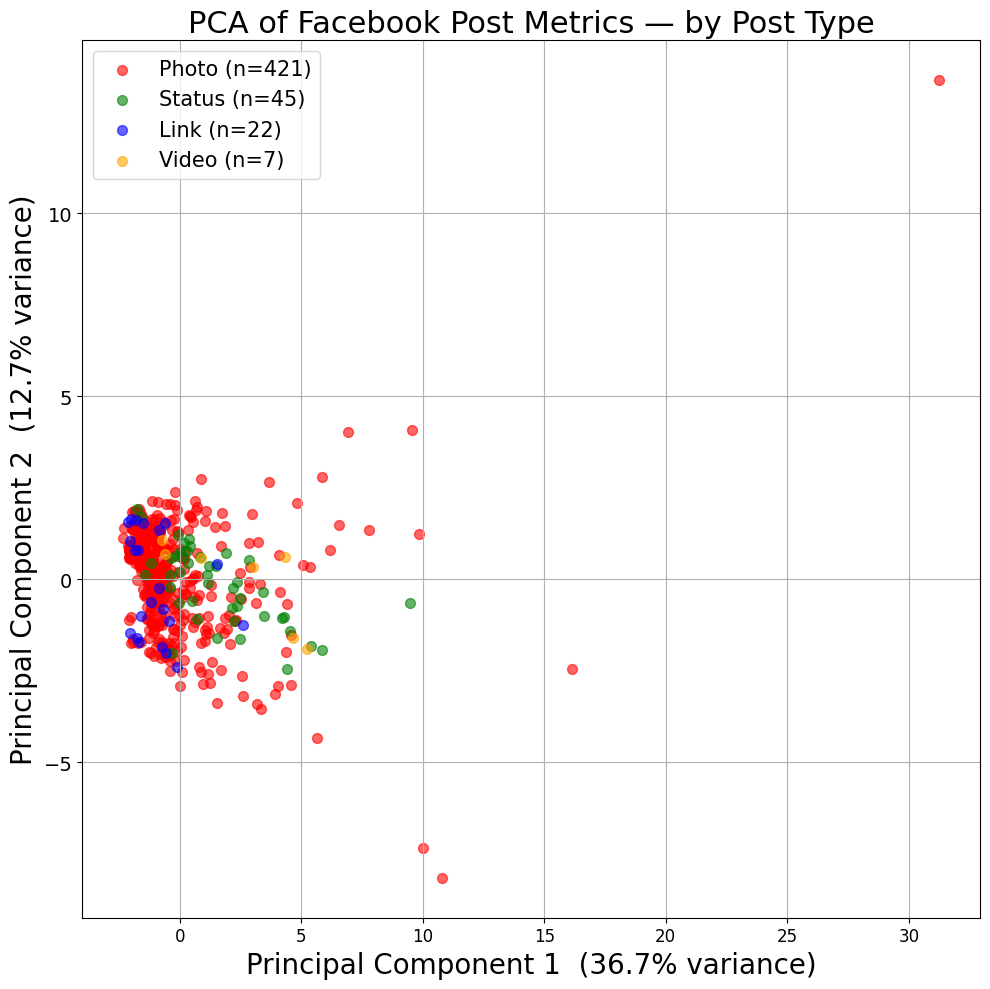

Plot saved as pca_facebook.png


In [8]:
plt.figure(figsize=(10, 10))

plt.xlabel('Principal Component 1  ({:.1%} variance)'.format(pc1_var), fontsize=20)
plt.ylabel('Principal Component 2  ({:.1%} variance)'.format(pc2_var), fontsize=20)
plt.title('PCA of Facebook Post Metrics — by Post Type', fontsize=22)
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)

colors = {
    'Photo':  ('r', 'Photo'),
    'Status': ('g', 'Status'),
    'Link':   ('b', 'Link'),
    'Video':  ('orange', 'Video')
}

for label, (color, name) in colors.items():
    mask = fb_dataset['Type'] == label
    plt.scatter(
        pca_df.loc[mask, 'PC1'],
        pca_df.loc[mask, 'PC2'],
        c=color,
        s=50,
        alpha=0.6,
        label='{} (n={})'.format(name, mask.sum())
    )

plt.legend(prop={'size': 15})
plt.grid()
plt.tight_layout()
plt.savefig('pca_facebook.png', dpi=150)
plt.show()

print('Plot saved as pca_facebook.png')

---
## Summary & Interpretation



### What the plot tells us:
- **PC1** is loaded positively by almost all engagement metrics, so posts further right got more reach and interaction.
- **PC2** is mostly driven by `Page total likes` and `Post Month`, i.e. *when* the post was published.
- The four post types **overlap heavily** — unlike the Iris and Wine datasets, post type is *not* clearly separated by these metrics.
- Photo posts make up most of the data (421 of 495), so they cover most of the plot; the few Video and Link posts are scattered.
- Only ~49% of the variance is kept in 2D, so more components would be needed to represent this data well.

### Key Takeaways:
> 18 features were reduced to 2 components, preserving ~49% of the variance
>
> The classes do not form distinct clusters, so post type is not what mainly drives these metrics
>
> PC1 works as a single "engagement score" for a post